In [79]:
import pandas as pd
import numpy as np
import seaborn as sns
from scipy.ndimage import gaussian_filter1d
from seaborn import objects as so


In [18]:
epoch = 30

In [19]:
df = pd.read_csv('/Users/jfi22496/Documents/code/pandda_2_paper_figures/data/ML Training Metadata For Plotting/event_scoring.csv')
df = df[df['table'] == 'pandda_2']


In [20]:
pr = []
for _system in df['system'].unique():
    system_prs = []
    best_df = df[(df['epoch'] == epoch) & (df['system'] == _system)]
    #for cutoff in [x for x in np.linspace(0.1, 1.0, num=100)] + [x for x in np.linspace(0., 0.1, num=1000)]:
    for cutoff in [0.0] + [x for x in np.geomspace(1e-12, 0.1, num=1000)]+ [1-x for x in np.geomspace(1e-12, 0.9, num=1000)] + [1.0]:
        # true_hit_best_df = best_df[best_df['y'] > 0.9]
        # negative_best_df = best_df[best_df['y'] <= 0.1]
        true_hit_best_df = best_df[best_df['Confidence'] == 'High']
        negative_best_df = best_df[best_df['Confidence'] == 'Low']
        true_hit_df = true_hit_best_df[true_hit_best_df['y_hat'] > cutoff]
        false_hit_df = negative_best_df[negative_best_df['y_hat'] > cutoff]
        true_negative_df = negative_best_df[negative_best_df['y_hat'] <=cutoff]
        false_negative_df = true_hit_best_df[true_hit_best_df['y_hat'] <= cutoff]
        tp = len(true_hit_df)
        fp = len(false_hit_df)
        tn = len(true_negative_df)
        fn = len(false_negative_df)
        
        base_prec = len(true_hit_best_df ) / (len(true_hit_best_df) + len(negative_best_df))

        if tp+fp == 0:
            prec= 0.0
        else:
            prec = tp / (tp+fp)
        if tp+fn == 0:
            recall = 0.0
        else:
            recall = tp / (tp+fn)
        if (fp+tn) == 0:
            fpr = 0.0
        else:
            fpr = fp / (fp+tn)
            
        if tp + fp == 0:
            contamination = 1.0
        else:
            contamination = fp / (tp+fp)
        base_contamination = len(negative_best_df) / (len(negative_best_df) + len(true_hit_best_df))
        
        system_prs.append(
            {
                'Cutoff': cutoff,
                'Precision': prec ,
                'Relative Precision': prec / base_prec,
                'Recall': recall,
                'False Positive Rate': fpr,
                'Contamination': contamination,
                'Relative Contamination': contamination / base_contamination,
                'System': _system
            }
        )
    smoothed_precision = gaussian_filter1d(np.array([_x['Precision'] for _x in system_prs]), sigma=0.1)
    smoothed_rel_precision = gaussian_filter1d(np.array([_x['Relative Precision'] for _x in system_prs]), sigma=0.1)

    smoothed_recall = gaussian_filter1d(np.array([_x['Recall'] for _x in system_prs]), sigma=0.1)

    for _x, _prec, _rel_prec, _rec in zip(system_prs, smoothed_precision ,smoothed_rel_precision, smoothed_recall):
        _x['Smoothed Relative Precision'] = _rel_prec
        _x['Smoothed Precision'] = _prec

        _x['Smoothed Recall'] = _rec
        
        pr.append(_x)
pr_df = pd.DataFrame(pr)
best_fpr_99 = pr_df[pr_df['Recall'] > 0.99]['False Positive Rate'].min()
best_fpr_95 = pr_df[pr_df['Recall'] > 0.95]['False Positive Rate'].min()

print([best_fpr_99, best_fpr_95])


[np.float64(0.0), np.float64(0.0)]


# Plot the cumulative frequency of score sorted hit events

In [36]:
records = []
for _system in df['system'].unique():
    best_df = df[(df['epoch'] == epoch) & (df['system'] == _system)]
    event_num = 0
    not_low_num = 0
    # num_not_low = len(best_df[best_df['Confidence'] != 'Low'])
    num_not_low = len(best_df[best_df['Confidence'] == 'High'])

    for _idx, _row in best_df.sort_values(by='y_hat', ascending=False).iterrows():
        event_num += 1
        # if _row['Confidence'] != 'Low':
        if _row['Confidence'] == 'High':

            not_low_num += 1
        records.append(
            {
                'event_num': event_num,
                'system': _system,
                'percent': not_low_num / num_not_low,
                'hits': not_low_num,
            }
        )
plot_df = pd.DataFrame(records)
plot_df

,event_num,system,percent,hits
0,1,BRD1A,0.000000,0
1,2,BRD1A,0.000000,0
2,3,BRD1A,0.000000,0
3,4,BRD1A,0.018519,1
4,5,BRD1A,0.037037,2
...,...,...,...,...
3835,877,NSP16,1.000000,52
3836,878,NSP16,1.000000,52
3837,879,NSP16,1.000000,52
3838,880,NSP16,1.000000,52


<Axes: xlabel='event_num', ylabel='percent'>

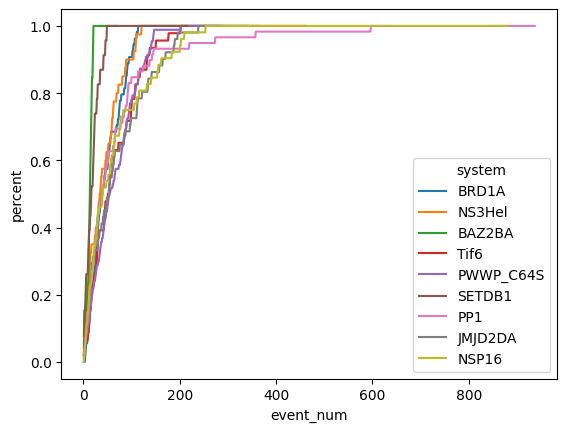

In [37]:
sns.lineplot(data=plot_df, x='event_num', y='percent', hue='system')

<Axes: xlabel='event_num', ylabel='hits'>

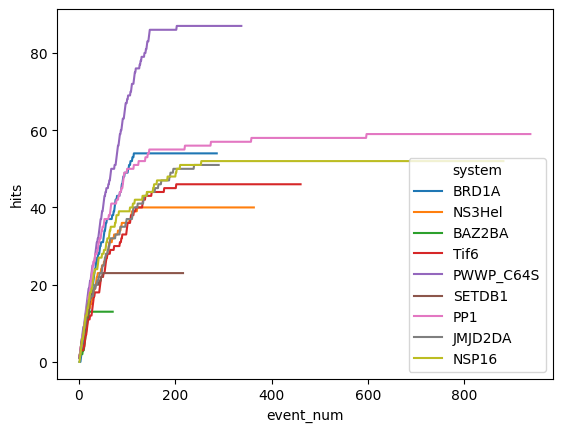

In [38]:
sns.lineplot(data=plot_df, x='event_num', y='hits', hue='system')

<Axes: xlabel='event_num', ylabel='hits'>

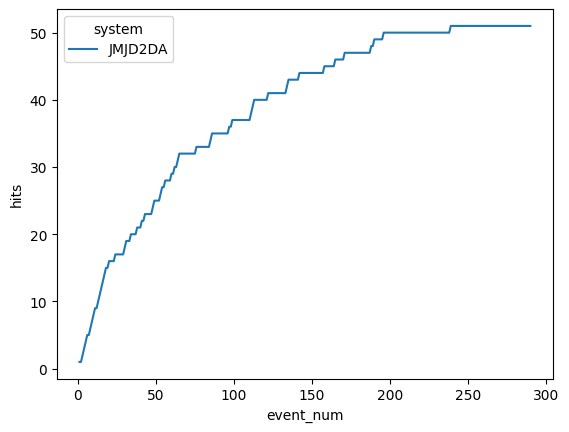

In [39]:
sns.lineplot(data=plot_df[plot_df['system'] == 'JMJD2DA'], x='event_num', y='hits', hue='system')

<Axes: xlabel='event_num', ylabel='hits'>

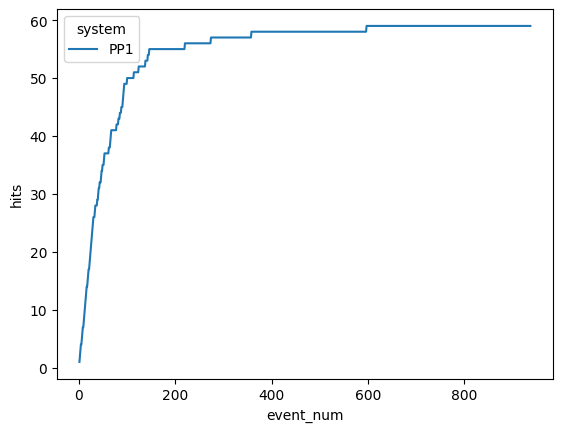

In [40]:
sns.lineplot(data=plot_df[plot_df['system'] == 'PP1'], x='event_num', y='hits', hue='system')

In [ ]:
records = []
for _system in df['system'].unique():
    system_best_df = df[(df['epoch'] == epoch) & (df['system'] == _system)]

    sorted_df = system_best_df.sort_values(by='y_hat', ascending=False,).reset_index()
    # print(sorted_df['Confidence'])
    # print(sorted_df.iloc[:0])
    num_hits = len(sorted_df[sorted_df['Confidence'] == 'High'])

    recall_at_idx = {_idx: len(sorted_df.iloc[:_idx+1][sorted_df.iloc[:_idx+1]['Confidence'] == 'High']) / num_hits for _idx, _row in sorted_df.iterrows()}
    # print(recall_at_idx)

    # recall_at_90_idx = min([x for x in recall_at_idx if recall_at_idx[x] > 0.9])
    # events_per_hit_at_90_recall = len(sorted_df.iloc[:recall_at_90_idx+1]) / len(sorted_df.iloc[:recall_at_90_idx+1][sorted_df.iloc[:recall_at_90_idx+1]['Confidence'] == 'High']) 

    # recall_at_95_idx = min([x for x in recall_at_idx if recall_at_idx[x] > 0.95])
    # events_per_hit_at_95_recall = len(sorted_df.iloc[:recall_at_95_idx+1]) / len(sorted_df.iloc[:recall_at_95_idx+1][sorted_df.iloc[:recall_at_95_idx+1]['Confidence'] == 'High']) 

    # recall_at_99_idx = min([x for x in recall_at_idx if recall_at_idx[x] > 0.99])
    # events_per_hit_at_99_recall = len(sorted_df.iloc[:recall_at_99_idx+1]) / len(sorted_df.iloc[:recall_at_99_idx+1][sorted_df.iloc[:recall_at_99_idx+1]['Confidence'] == 'High']) 

    # recall_at_100_idx = min([x for x in recall_at_idx if recall_at_idx[x] > 0.99999])
    # events_per_hit_at_100_recall = len(sorted_df.iloc[:recall_at_100_idx+1]) / len(sorted_df.iloc[:recall_at_100_idx+1][sorted_df.iloc[:recall_at_100_idx+1]['Confidence'] == 'High']) 

    recalls = [("90%", 0.9), ("95%", 0.95), ("99%", 0.99)]
    # recalls.reverse()
    for recall_string, recall in recalls:
        recall_at_idx_x = min([x for x in recall_at_idx if recall_at_idx[x] > recall])
        events_per_hit = len(sorted_df.iloc[:recall_at_idx_x+1]) / len(sorted_df.iloc[:recall_at_idx_x+1][sorted_df.iloc[:recall_at_idx_x+1]['Confidence'] == 'High']) 



        records.append(
            {
                'System': _system,
                'Events per Hit': events_per_hit,
                '% All Hits': recall_string
            }
        )
    records.append(
            {
                'System': _system,
                'Events per Hit': len(sorted_df) / num_hits,
                '% All Hits': 'Baseline - no scoring'
                # 'events_per_hit_at_90_recall': events_per_hit_at_90_recall,
                # 'events_per_hit_at_95_recall': events_per_hit_at_95_recall,
                # 'events_per_hit_at_99_recall': events_per_hit_at_99_recall,
                # 'events_per_hit_at_100_recall': events_per_hit_at_100_recall

            }
        )
    

plot_df = pd.DataFrame(records)

In [109]:
# sns.barplot(
#     data=plot_df,
#     x='system',
#     y='events_per_hit_at_100_recall'
# )
# sns.barplot(
#     data=plot_df,
#     x='system',
#     y='events_per_hit_at_99_recall'
# )
# sns.barplot(
#     data=plot_df,
#     x='system',
#     y='events_per_hit_at_95_recall'
# )
# sns.barplot(
#     data=plot_df,
#     x='system',
#     y='events_per_hit_at_90_recall'
# )


In [110]:
plot_df

,System,Events per Hit,% All Hits
0,BRD1A,1.938776,90%
1,BRD1A,2.057692,95%
2,BRD1A,2.111111,99%
3,NS3Hel,2.837838,90%
4,NS3Hel,2.820513,95%
5,NS3Hel,3.025000,99%
6,BAZ2BA,1.666667,90%
7,BAZ2BA,1.615385,95%
8,BAZ2BA,1.615385,99%
9,Tif6,3.166667,90%


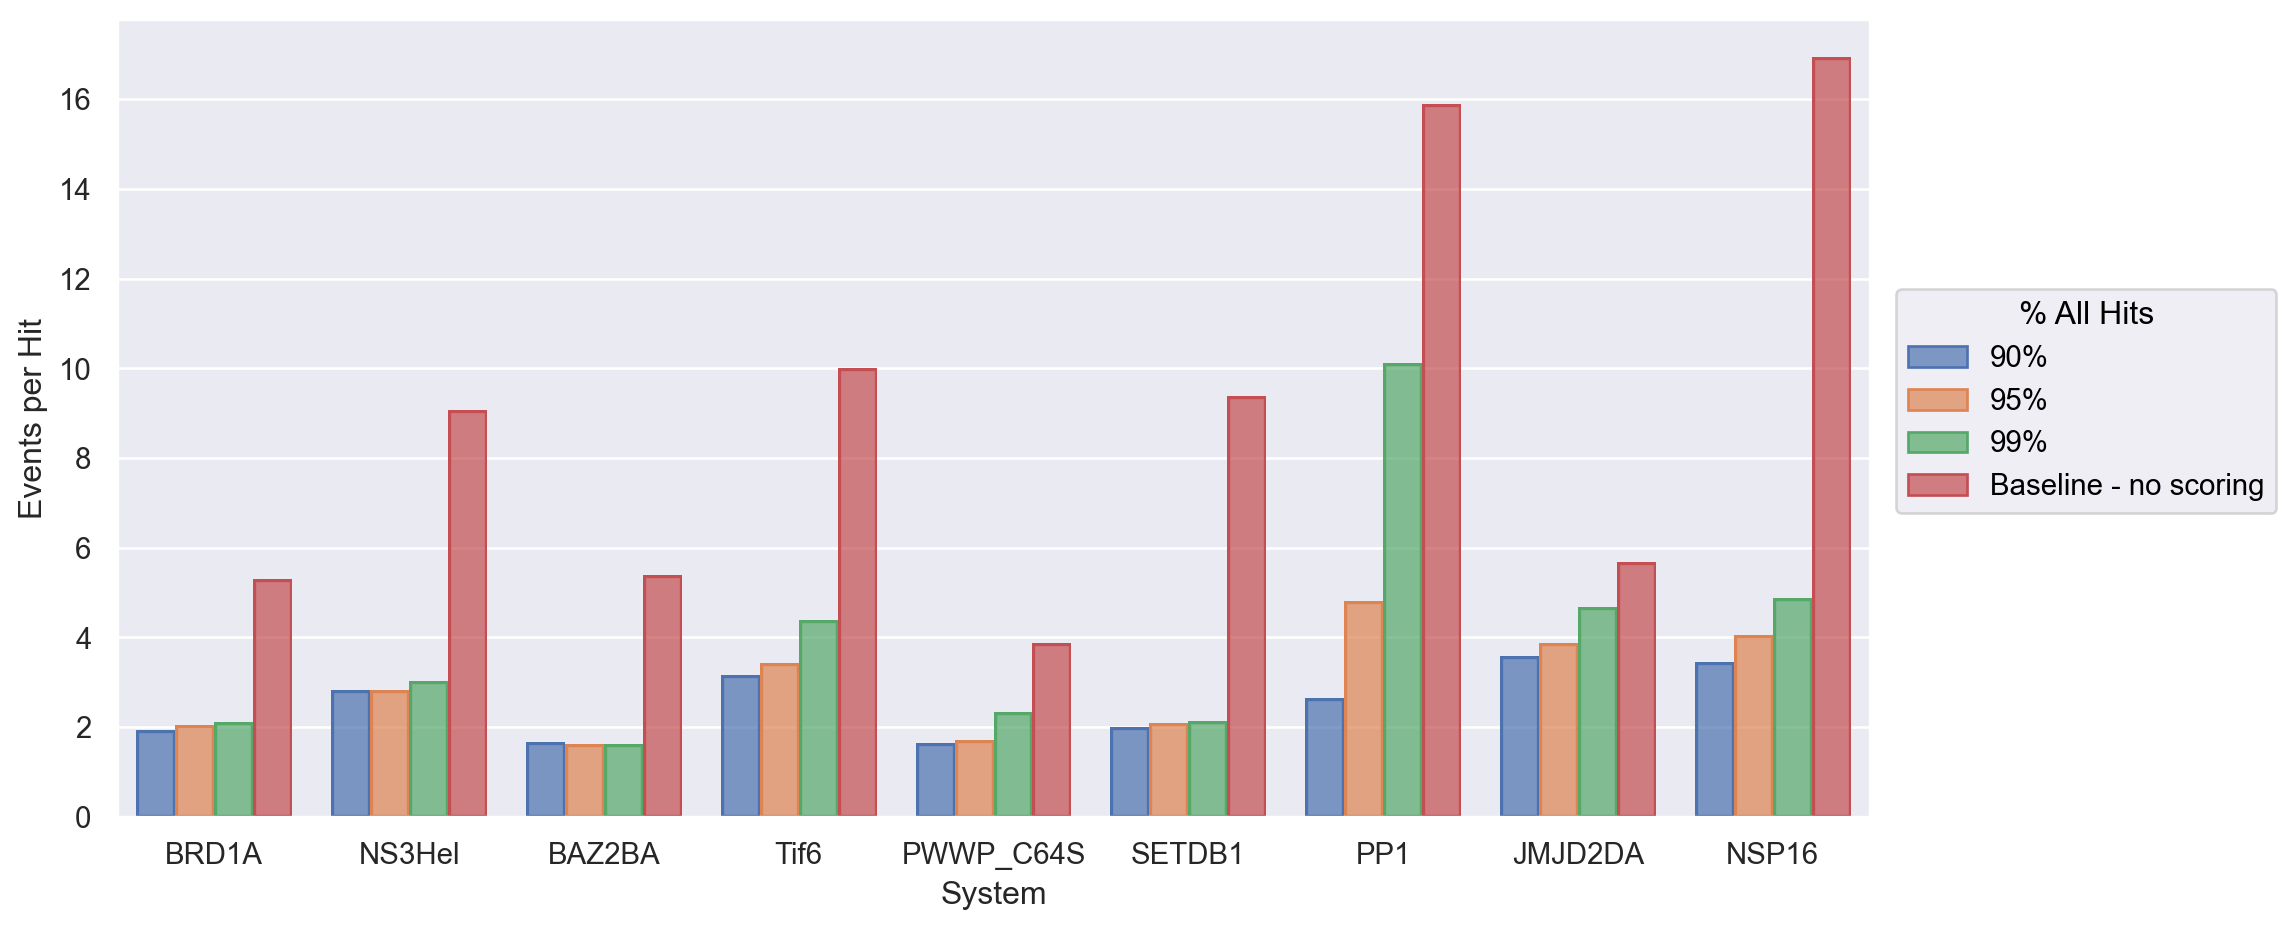

In [123]:

so.Plot(plot_df, x="System", y='Events per Hit', color='% All Hits').add(so.Bar(), so.Dodge()).layout(size=(10,5))


sns.barplot()